# RQ1 Walkthrough — Chunking and Retrieval on a Single Report

This notebook provides a **qualitative inspection** of the RQ1 pipeline by running it on a single company report and query. It complements the quantitative evaluation in `05_rq1_chunking_evaluation.ipynb`.

> **Purpose in the thesis:** This walkthrough makes abstract metrics concrete by showing exactly what the pipeline produces at each stage — from raw text segmentation to ranked retrieval results.

### What This Notebook Demonstrates

1. How each chunking strategy (fixed, structure-aware, semantic) and size (256, 512, 1024) segments the same report — total chunks, token distributions, min/max.
2. What representative chunks look like: text content, page spans, and heading hierarchy metadata.
3. How the six retrieval methods rank chunks for one sample query — which passages each method surfaces and at which rank.
4. How rankings shift between dense, sparse, and RRF fusion — visualising the complementarity of the retrieval paradigms.

### Sample

**Company:** Shell (2024 sustainability report) — chosen as a representative large European energy company with comprehensive ESRS disclosures.

### Notebook Structure

1. Setup and sample selection
2. Chunk overview across all strategy/size combinations
3. Inspect representative chunks
4. Retrieval comparison across all six methods
5. Retrieved chunks per method
6. Ranking shifts across base methods
7. Interpretation

## 1. Setup and Sample Selection

Load all 17 reports and the 204-sample Golden Standard, then select one company and its first query for the walkthrough.

In [1]:
# ---------------------------------------------------------------------------
# Path setup and imports
# ---------------------------------------------------------------------------
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# --- Thesis-quality plot defaults ---
plt.rcParams.update({
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "figure.figsize": (10, 5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
})

from rag.config.settings import PipelineConfig
from rag.data.loaders import load_reports, load_golden_samples
from rag.chunking.strategies import build_chunks_for_config
from rag.indexing.embedder import EmbeddingService
from rag.indexing.qdrant_index import QdrantChunkIndex
from rag.retrieval.methods import Retriever

# Load the full corpus and Golden Standard.
reports = load_reports()
samples = load_golden_samples()

# Select one company and its first Golden Standard query.
SAMPLE_COMPANY = "Shell"
SAMPLE_QUERY = next(s.question for s in samples if s.company == SAMPLE_COMPANY)

print(f"Company : {SAMPLE_COMPANY}")
print(f"Query   : {SAMPLE_QUERY[:120]}...")

Company : Shell
Query   : How has the undertaking conducted its double materiality assessment, and which sustainability matters were identified as...


## 2. Chunk Overview Across All Strategy/Size Combinations

We build chunks for all **9 strategy x size combinations** on Shell's report and compare total chunk counts, mean/std token lengths, and min/max sizes.

**What to look for:**

- **`fixed`** chunking always produces near-uniform token counts (very low std), because it splits at a fixed window regardless of content.
- **`structure_aware`** chunk counts decrease with larger target sizes because bigger windows can absorb entire subsections; the high std reflects adaptation to heading boundaries.
- **`semantic`** chunking tends to produce many more, smaller chunks because it splits on sentence-level coherence drops — even after greedy merging, some groups remain small.

In [2]:
# ---------------------------------------------------------------------------
# Build chunks for all 9 strategy/size combinations on the sample report.
# Store chunks in a dict keyed by (strategy, size) for later retrieval
# comparison, and collect summary statistics into a DataFrame.
# ---------------------------------------------------------------------------
records = []
all_chunks_by_cfg = {}

for strategy in ["fixed", "structure_aware", "semantic"]:
    for size in [256, 512, 1024]:
        cfg = PipelineConfig(chunk_strategy=strategy, chunk_size=size, retrieval_method="hybrid_rrf")
        chunks, stats = build_chunks_for_config({SAMPLE_COMPANY: reports[SAMPLE_COMPANY]}, cfg)
        all_chunks_by_cfg[(strategy, size)] = chunks
        records.append({
            "strategy": strategy, "size": size,
            "total_chunks": stats.total_chunks,
            "mean_tokens": round(stats.mean_tokens, 1),
            "std_tokens": round(stats.std_tokens, 1),
            "min_tokens": stats.min_tokens,
            "max_tokens": stats.max_tokens,
        })

chunk_overview = pd.DataFrame(records).sort_values(["strategy", "size"])
chunk_overview

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


,strategy,size,total_chunks,mean_tokens,std_tokens,min_tokens,max_tokens
0,fixed,256,853,255.8,2.1,200,258
1,fixed,512,427,511.1,15.1,200,514
2,fixed,1024,214,1020.0,56.2,200,1026
6,semantic,256,1123,181.4,78.3,2,257
7,semantic,512,724,277.9,176.9,2,513
8,semantic,1024,571,349.2,333.4,2,1025
3,structure_aware,256,970,217.2,63.7,5,258
4,structure_aware,512,486,426.3,127.5,5,514
5,structure_aware,1024,245,836.0,269.5,5,1025


## 3. Inspect Representative Chunks

Preview the first few chunks from `structure_aware` / 512 tokens — a representative "middle ground" configuration that respects the document's Markdown heading hierarchy while keeping chunks at a moderate size.

**What to look for:**

- The **`headers`** column shows the heading breadcrumb trail (e.g., "Sustainability Statements > General disclosures > GHG emissions"). This metadata is only populated for `structure_aware` chunking.
- **Token counts vary** because sections have different natural lengths; chunks are split only when they exceed the token ceiling.
- **`page_start`–`page_end`** spans show how chunks map back to the original PDF pages.

In [3]:
# ---------------------------------------------------------------------------
# Preview helper: display the first n chunks for a given strategy/size.
# ---------------------------------------------------------------------------
def preview_chunks(strategy: str, size: int, n: int = 3):
    """Show chunk_id, token count, page span, headers, and a text preview."""
    chunks = all_chunks_by_cfg[(strategy, size)]
    rows = []
    for c in chunks[:n]:
        rows.append({
            "chunk_id": c.chunk_id[:12],
            "tokens": c.token_count,
            "pages": f"{c.page_start}-{c.page_end}",
            "headers": " > ".join(c.header_hierarchy) if c.header_hierarchy else "",
            "text_preview": c.text[:300],
        })
    return pd.DataFrame(rows)

# Show 5 representative chunks from structure_aware / 512.
preview_chunks("structure_aware", 512, n=5)

,chunk_id,tokens,pages,headers,text_preview
0,237da278e79b,223,None-342,Sustainability Statements,# Sustainability Statements\n\n\n\n\n| 342 | G...
1,48d61d1ef698,470,342-342,Sustainability Statements > General disclosure...,### General basis for preparation of Sustainab...
2,1bdb6568ab25,369,342-342,Sustainability Statements > General disclosure...,### Understanding differences in reporting bou...
3,ae7e02a3b2bf,376,342-342,Sustainability Statements > General disclosure...,### Greenhouse gas (GHG) emissions\n\nThe GHG ...
4,d160cce7db5e,512,343-343,Sustainability Statements > General disclosure...,"### Other environmental, social and governance..."


## 4. Retrieval Comparison Across All Six Methods

Using `structure_aware` / 512 tokens as the base chunking configuration, we index all chunks in Qdrant and run the same query through all six retrieval methods. This **isolates the effect of the retrieval method** while holding chunking constant.

| Method | Description |
|---|---|
| **Dense** | Cosine similarity on `text-embedding-3-large` embeddings (3,072 dims) |
| **Dense + Rerank** | Dense retrieval of 3x candidates, then cross-encoder re-scoring |
| **Sparse (BM25)** | Okapi BM25 term-frequency matching (Robertson et al., 1994) |
| **Sparse + Rerank** | BM25 with cross-encoder re-scoring |
| **Hybrid RRF** | Reciprocal Rank Fusion (k=60) combining dense + sparse (Cormack et al., 2009) |
| **Hybrid + Rerank** | RRF with cross-encoder re-scoring |

In [4]:
# ---------------------------------------------------------------------------
# Index chunks and run the same query through all 6 retrieval methods.
# ---------------------------------------------------------------------------
BASE_STRATEGY = "structure_aware"
BASE_SIZE = 512
chunks = all_chunks_by_cfg[(BASE_STRATEGY, BASE_SIZE)]

# Embed and index in Qdrant.
embedder = EmbeddingService(load_cache=False)
qdrant = QdrantChunkIndex(dims=embedder.dims)
collection_name = qdrant.collection_name(BASE_STRATEGY, BASE_SIZE)
qdrant.recreate_collection(collection_name)
vectors = embedder.embed_texts([c.text for c in chunks])
qdrant.upsert_chunks(collection_name, chunks, vectors)

# Create a Retriever instance.
cfg = PipelineConfig(
    chunk_strategy=BASE_STRATEGY, chunk_size=BASE_SIZE,
    retrieval_method="dense", top_k=15,
)
r = Retriever(chunks=chunks, config=cfg, embedder=embedder, qdrant=qdrant)

# Retrieve top-15 for each method.
METHODS = ["dense", "dense_rerank", "sparse", "sparse_rerank", "hybrid_rrf", "hybrid_rerank"]
method_to_hits = {}

for method in METHODS:
    r.config = PipelineConfig(
        chunk_strategy=BASE_STRATEGY, chunk_size=BASE_SIZE,
        retrieval_method=method, top_k=15,
    )
    try:
        method_to_hits[method] = r.retrieve(SAMPLE_QUERY, company=SAMPLE_COMPANY, top_k=15)
    except Exception as exc:
        print(f"  Skipping {method}: {exc}")

print(f"Completed retrieval for {len(method_to_hits)}/{len(METHODS)} methods: {list(method_to_hits.keys())}")

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: cross-encoder/ms-marco-MiniLM-L-6-v2
Key                          | Status     |  | 
-----------------------------+------------+--+-
bert.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Completed retrieval for 6/6 methods: ['dense', 'dense_rerank', 'sparse', 'sparse_rerank', 'hybrid_rrf', 'hybrid_rerank']


## 5. Retrieved Chunks per Method

The tables below show the **top-10 retrieved chunks** for each method, including rank, score, page span, and a text preview.

**How to read the tables:**

- **rank**: Position in the result list (1 = top). Lower is better.
- **score**: Retrieval score. The scale differs by method: dense uses cosine similarity (0–1), BM25 uses term-frequency scores (unbounded), RRF uses reciprocal-rank scores (~0.01–0.03), and reranked variants use cross-encoder logits.
- **chunk_id**: First 12 characters of the SHA-256 hash identifying each chunk.

**Key observations to look for:**

- Do all methods agree on the top-1 chunk, or do they surface different passages?
- Reranked variants share the same candidate pool as their base method but reorder them.
- BM25 tends to favour chunks with exact ESRS terminology; dense retrieval captures semantic paraphrases.

In [5]:
# ---------------------------------------------------------------------------
# Display the top-10 retrieved chunks for each retrieval method.
# ---------------------------------------------------------------------------
import math

def hits_to_df(method: str):
    """Convert retrieval hits into a display DataFrame."""
    rows = []
    for h in method_to_hits.get(method, []):
        score_val = h.score
        score_display = round(score_val, 4) if not math.isnan(score_val) else "NaN"
        rows.append({
            "method": method, "rank": h.rank,
            "score": score_display,
            "chunk_id": h.chunk.chunk_id[:12],
            "pages": f"{h.chunk.page_start}-{h.chunk.page_end}",
            "text_preview": h.chunk.text[:220],
        })
    return pd.DataFrame(rows)

for m in METHODS:
    print(f"\n{'='*80}")
    print(f"  {m.upper()}")
    print(f"{'='*80}")
    display(hits_to_df(m).head(10))


  DENSE


,method,rank,score,chunk_id,pages,text_preview
0,dense,1,0.6793,0821d73159cf,357-357,### Other methodological notes\n\nWe engage wi...
1,dense,2,0.6464,663349512d35,350-351,well as whether such matters trigger or could ...
2,dense,3,0.6282,84b6b565e7ea,358-358,uneration policies linked to sustainability (p...
3,dense,4,0.6251,dc4dd796483d,354-354,## Current and anticipated financial effects\n...
4,dense,5,0.6240,8b6ba3dc2317,351-351,materiality assessment process uses qualitativ...
5,dense,6,0.6172,5095339d359f,354-355,we assess potential magnitude on a gross basis...
6,dense,7,0.5864,e57fd7ceee7c,358-359,135-144). §53(e)-(f): Extent to which the proc...
7,dense,8,0.5838,237da278e79b,None-342,# Sustainability Statements\n\n\n\n\n| 342 | G...
8,dense,9,0.5741,2f64bd4a81d8,354-354,"### 2. Identify impacts, risks and opportuniti..."
9,dense,10,0.5730,b720077462e3,361-361,impacts and channels for value chain workers t...



  DENSE_RERANK


,method,rank,score,chunk_id,pages,text_preview
0,dense_rerank,1,0.8983,0821d73159cf,357-357,### Other methodological notes\n\nWe engage wi...
1,dense_rerank,2,0.8415,8a5c4d1801bd,438-439,### Emphasis of matter - The double materialit...
2,dense_rerank,3,0.7732,663349512d35,350-351,well as whether such matters trigger or could ...
3,dense_rerank,4,0.7607,dc4dd796483d,354-354,## Current and anticipated financial effects\n...
4,dense_rerank,5,0.7298,84b6b565e7ea,358-358,uneration policies linked to sustainability (p...
5,dense_rerank,6,0.7181,f22d11ba37c1,350-350,"informed by the views, interests and rights of..."
6,dense_rerank,7,0.7115,8b6ba3dc2317,351-351,materiality assessment process uses qualitativ...
7,dense_rerank,8,0.7042,5095339d359f,354-355,we assess potential magnitude on a gross basis...
8,dense_rerank,9,0.7021,a35e20de04d3,439-439,## Our approach\n\nThe objective of a limited ...
9,dense_rerank,10,0.6558,2cee16beefd6,355-355,or depict and the relevance of the data point ...



  SPARSE


...

,method,rank,score,chunk_id,pages,text_preview
0,sparse_rerank,1,0.9424,f22d11ba37c1,350-350,"informed by the views, interests and rights of..."
1,sparse_rerank,2,0.8697,663349512d35,350-351,well as whether such matters trigger or could ...
2,sparse_rerank,3,0.8523,8a5c4d1801bd,438-439,### Emphasis of matter - The double materialit...
3,sparse_rerank,4,0.7545,5095339d359f,354-355,we assess potential magnitude on a gross basis...
4,sparse_rerank,5,0.7395,8b6ba3dc2317,351-351,materiality assessment process uses qualitativ...
5,sparse_rerank,6,0.7244,4f65289b1b5e,397-397,## Biodiversity and ecosystems (E4)\n\n## Our ...
6,sparse_rerank,7,0.7205,c2e30ba63efc,414-414,"## Incidents, complaints and severe human righ..."
7,sparse_rerank,8,0.7082,0821d73159cf,357-357,### Other methodological notes\n\nWe engage wi...
8,sparse_rerank,9,0.7043,e7ac9cdf9207,408-408,## Social\n\n### Own workforce (S1)\n\n## Our ...
9,sparse_rerank,10,0.6868,dc4dd796483d,354-354,## Current and anticipated financial effects\n...



  HYBRID_RRF


,method,rank,score,chunk_id,pages,text_preview
0,hybrid_rrf,1,0.0323,663349512d35,350-351,well as whether such matters trigger or could ...
1,hybrid_rrf,2,0.0311,0821d73159cf,357-357,### Other methodological notes\n\nWe engage wi...
2,hybrid_rrf,3,0.0308,dc4dd796483d,354-354,## Current and anticipated financial effects\n...
3,hybrid_rrf,4,0.0308,8b6ba3dc2317,351-351,materiality assessment process uses qualitativ...
4,hybrid_rrf,5,0.0301,f22d11ba37c1,350-350,"informed by the views, interests and rights of..."
5,hybrid_rrf,6,0.0301,5095339d359f,354-355,we assess potential magnitude on a gross basis...
6,hybrid_rrf,7,0.0298,8a5c4d1801bd,438-439,### Emphasis of matter - The double materialit...
7,hybrid_rrf,8,0.0267,a35e20de04d3,439-439,## Our approach\n\nThe objective of a limited ...
8,hybrid_rrf,9,0.0250,2cee16beefd6,355-355,or depict and the relevance of the data point ...
9,hybrid_rrf,10,0.0249,ca38d179f6ce,353-353,### Risk factors\n\nClimate change and the ene...



  HYBRID_RERANK


,method,rank,score,chunk_id,pages,text_preview
0,hybrid_rerank,1,0.8869,8a5c4d1801bd,438-439,### Emphasis of matter - The double materialit...
1,hybrid_rerank,2,0.8709,0821d73159cf,357-357,### Other methodological notes\n\nWe engage wi...
2,hybrid_rerank,3,0.8488,663349512d35,350-351,well as whether such matters trigger or could ...
3,hybrid_rerank,4,0.8378,f22d11ba37c1,350-350,"informed by the views, interests and rights of..."
4,hybrid_rerank,5,0.8085,dc4dd796483d,354-354,## Current and anticipated financial effects\n...
5,hybrid_rerank,6,0.7706,8b6ba3dc2317,351-351,materiality assessment process uses qualitativ...
6,hybrid_rerank,7,0.7635,5095339d359f,354-355,we assess potential magnitude on a gross basis...
7,hybrid_rerank,8,0.7428,a35e20de04d3,439-439,## Our approach\n\nThe objective of a limited ...
8,hybrid_rerank,9,0.6671,2cee16beefd6,355-355,or depict and the relevance of the data point ...
9,hybrid_rerank,10,0.6559,4f65289b1b5e,397-397,## Biodiversity and ecosystems (E4)\n\n## Our ...


## 6. Ranking Shifts Across Base Methods

For chunks that appear in the top results of **all three base methods** (dense, sparse, hybrid RRF), we compare how their rank changes. This visualises whether RRF fusion successfully combines the strengths of dense and sparse retrieval.

**Why only the three base methods?** Reranked variants use the same candidate pools — including them would add clutter without new information about retrieval complementarity.

**How to read the plot:**

- Each point on the x-axis is a chunk (identified by truncated chunk_id).
- The y-axis shows rank (inverted: rank 1 at top).
- Lines connect the same chunk across methods.
- **Converging lines** indicate agreement on importance; **diverging lines** show where dense and sparse disagree — these are the cases where RRF adds the most value.

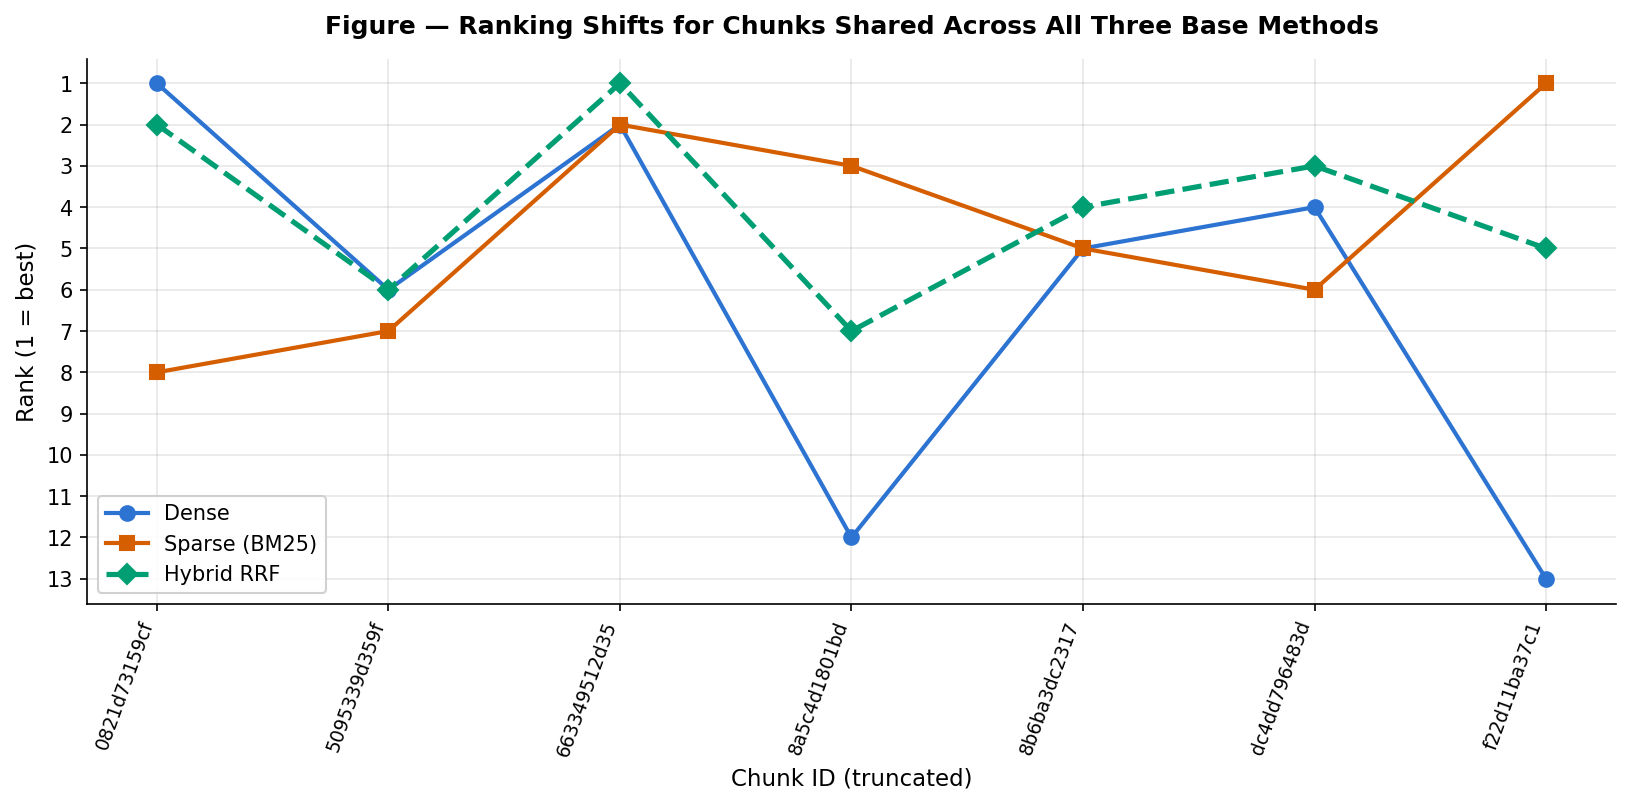

In [6]:
# ---------------------------------------------------------------------------
# Ranking shift visualisation: compare how the same chunks are ranked
# by dense, sparse, and hybrid RRF retrieval.
# ---------------------------------------------------------------------------
dense_df  = hits_to_df("dense")
sparse_df = hits_to_df("sparse")
rrf_df    = hits_to_df("hybrid_rrf")

def build_rank_map(df):
    """Map chunk_id -> rank from a hits DataFrame."""
    if df.empty:
        return {}
    return dict(zip(df["chunk_id"], df["rank"]))

rank_dense  = build_rank_map(dense_df)
rank_sparse = build_rank_map(sparse_df)
rank_rrf    = build_rank_map(rrf_df)

# Find chunks appearing in all three methods.
common_ids = sorted(set(rank_dense) & set(rank_sparse) & set(rank_rrf))[:20]
plot_rows = [{"chunk_id": cid, "Dense": rank_dense[cid],
              "Sparse (BM25)": rank_sparse[cid], "Hybrid RRF": rank_rrf[cid]}
             for cid in common_ids]
rank_cmp = pd.DataFrame(plot_rows)

if not rank_cmp.empty:
    fig, ax = plt.subplots(figsize=(11, 5.5))
    x = range(len(rank_cmp))

    method_styles = {
        "Dense":         {"color": "#2C73D2", "marker": "o", "linewidth": 2},
        "Sparse (BM25)": {"color": "#D55E00", "marker": "s", "linewidth": 2},
        "Hybrid RRF":    {"color": "#009E73", "marker": "D", "linewidth": 2.5, "linestyle": "--"},
    }

    for col, style in method_styles.items():
        ax.plot(x, rank_cmp[col], label=col, markersize=7, **style)

    ax.set_xticks(list(x))
    ax.set_xticklabels(rank_cmp["chunk_id"], rotation=70, ha="right", fontsize=9)
    ax.set_ylabel("Rank (1 = best)", fontsize=11)
    ax.set_xlabel("Chunk ID (truncated)", fontsize=11)
    ax.set_title("Figure — Ranking Shifts for Chunks Shared Across All Three Base Methods",
                 fontsize=12, fontweight="bold", pad=12)
    ax.legend(loc="best", framealpha=0.9)
    ax.invert_yaxis()
    ax.set_yticks(range(1, max(rank_cmp[["Dense", "Sparse (BM25)", "Hybrid RRF"]].max()) + 1))
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
else:
    print("No shared chunks across all three methods for this query.")

## 7. Interpretation

### Chunk Overview (Section 2)

`fixed` chunking produces uniform-size chunks (very low std), making it the most predictable strategy. `structure_aware` respects heading boundaries, resulting in variable sizes that match the document's logical structure. `semantic` splits on sentence-level coherence drops, often producing many small chunks even after greedy merging — this means 15 semantic chunks cover substantially less total text than 15 fixed-size chunks at the same nominal size.

### Dense vs. Sparse Retrieval (Section 5)

Dense retrieval (cosine similarity on `text-embedding-3-large` embeddings) captures **semantic similarity** — it can match paraphrases and conceptually related passages even without shared keywords. Sparse retrieval (BM25) captures **exact ESRS terminology** — it excels when the query and the relevant passage share specific technical terms like "double materiality assessment" or "GHG emissions". The two methods often surface different chunks in different orders, demonstrating their complementary strengths.

### RRF Fusion (Section 6)

Reciprocal Rank Fusion (k=60) combines dense and sparse rankings. Chunks ranked highly by **both** methods are promoted to the top; chunks found by only one method still appear but at lower combined ranks. The ranking shift plot makes this visible: when the dense and sparse lines diverge for a chunk, the RRF line typically falls between them (compromise ranking).

### Reranking (Sections 4–5)

Each base method has a reranked variant that retrieves a wider candidate pool (3x top_k), then a cross-encoder (`cross-encoder/ms-marco-MiniLM-L-6-v2`) re-scores those candidates. The cross-encoder considers full query-passage interaction (not just embedding similarity), which can improve precision at the top ranks. Notice that reranked variants often converge on the same top-1 chunk regardless of the base retrieval signal.

### Connection to RQ1

This walkthrough provides **qualitative evidence** that supports the quantitative findings in `05_rq1_chunking_evaluation.ipynb`. The abstract metrics (Recall@k, nDCG@10, MRR@10) become concrete when you can see exactly which passages each method retrieves and how the rankings differ.

---

*End of walkthrough. For the full quantitative RQ1 evaluation across all 54 configurations with statistical significance testing, see `05_rq1_chunking_evaluation.ipynb`.*